# Titanic EDA
Task 2 - Elevvo Data Analytics Internship

In this notebook I explore the Titanic dataset from Kaggle (`train.csv`, 891 passengers), clean it, and look at what affected the chance of survival.

Tools: pandas, matplotlib, seaborn

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Looking at the data

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [3]:
missing = df.isnull().sum()
missing = missing[missing > 0]
print(pd.DataFrame({"count": missing, "%": (missing / len(df) * 100).round(1)}))
print("duplicates:", df.duplicated().sum())

          count     %
Age         177  19.9
Cabin       687  77.1
Embarked      2   0.2
duplicates: 0


In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


3 columns have missing values:
- **Cabin** is missing in 77% of the rows so I won't try to fill it, I'll just keep if the passenger had a cabin or not
- **Age** is missing in about 20%. I'll fill it with the median age of people with the same title (Mr, Mrs, Miss, Master) since the title tells a lot about the age
- **Embarked** only has 2 missing so I'll use the most common port

Fare is also very skewed (median 14.45 but max 512).

## Cleaning

In [5]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df.loc[~df["Title"].isin(["Mr", "Miss", "Mrs", "Master"]), "Title"] = "Rare"
df.groupby("Title")["Age"].agg(["median", "count"])

,median,count
Title,,
Master,3.5,36
Miss,21.0,149
Mr,30.0,398
Mrs,35.0,109
Rare,48.5,22


In [6]:
df["Age"] = df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["HasCabin"] = df["Cabin"].notnull().astype(int)
df = df.drop(columns="Cabin")
df.isnull().sum().sum()

np.int64(0)

In [7]:
df[["Pclass", "Sex", "Embarked", "Title"]] = df[["Pclass", "Sex", "Embarked", "Title"]].astype("category")
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 80], labels=["Child", "Teen", "Young Adult", "Adult", "Senior"])
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,category
Name,object
Sex,category
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


## Analysis
Survived is 0/1 so its mean is the survival rate.

survival rate: 38.4 %


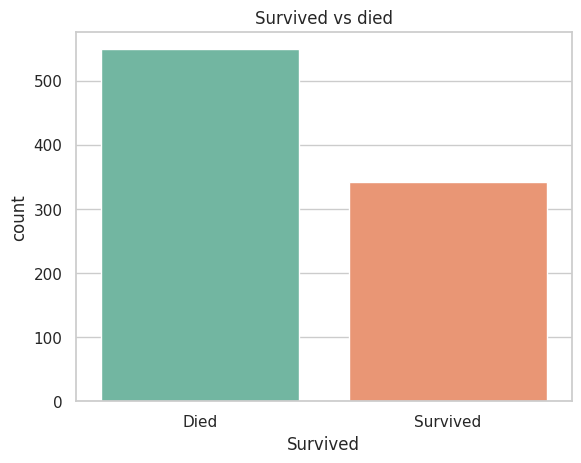

In [8]:
print("survival rate:", round(df["Survived"].mean() * 100, 1), "%")
sns.countplot(data=df, x="Survived", hue="Survived", palette="Set2", legend=False)
plt.xticks([0, 1], ["Died", "Survived"])
plt.title("Survived vs died")
plt.show()

In [9]:
for col in ["Sex", "Pclass", "Embarked", "Title"]:
  print(df.groupby(col, observed=True)["Survived"].mean().mul(100).round(1), "\n")

Sex
female    74.2
male      18.9
Name: Survived, dtype: float64 

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64 

Embarked
C    55.4
Q    39.0
S    33.9
Name: Survived, dtype: float64 

Title
Master    57.5
Miss      70.3
Mr        15.7
Mrs       79.4
Rare      34.8
Name: Survived, dtype: float64 



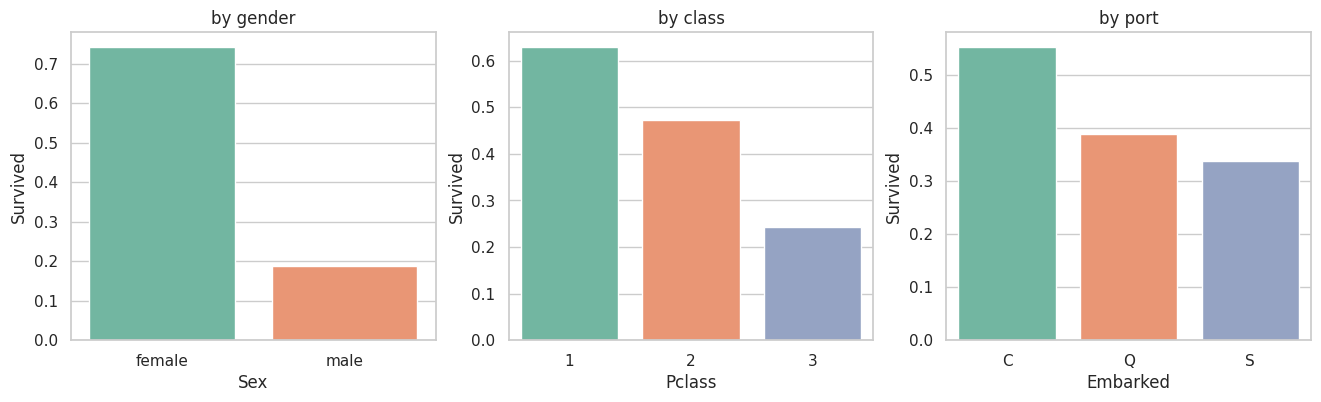

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=df, x="Sex", y="Survived", hue="Sex", palette="Set2", errorbar=None, legend=False, ax=ax[0])
sns.barplot(data=df, x="Pclass", y="Survived", hue="Pclass", palette="Set2", errorbar=None, legend=False, ax=ax[1])
sns.barplot(data=df, x="Embarked", y="Survived", hue="Embarked", palette="Set2", errorbar=None, legend=False, ax=ax[2])
ax[0].set_title("by gender")
ax[1].set_title("by class")
ax[2].set_title("by port")
plt.show()

Women survived way more than men (74% vs 19%) and 1st class did much better than 3rd. Let's look at both together (bonus heatmap):

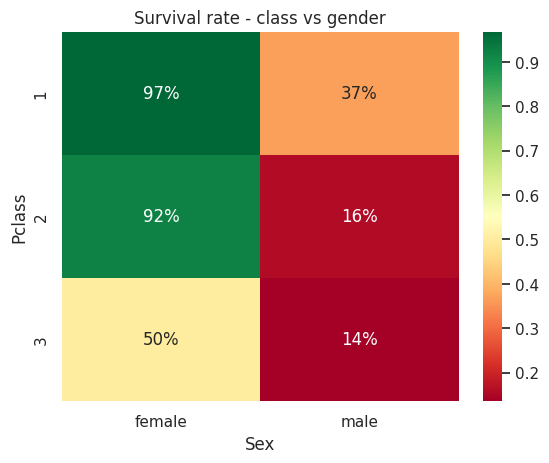

In [11]:
pivot = df.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean", observed=True)
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="RdYlGn")
plt.title("Survival rate - class vs gender")
plt.show()

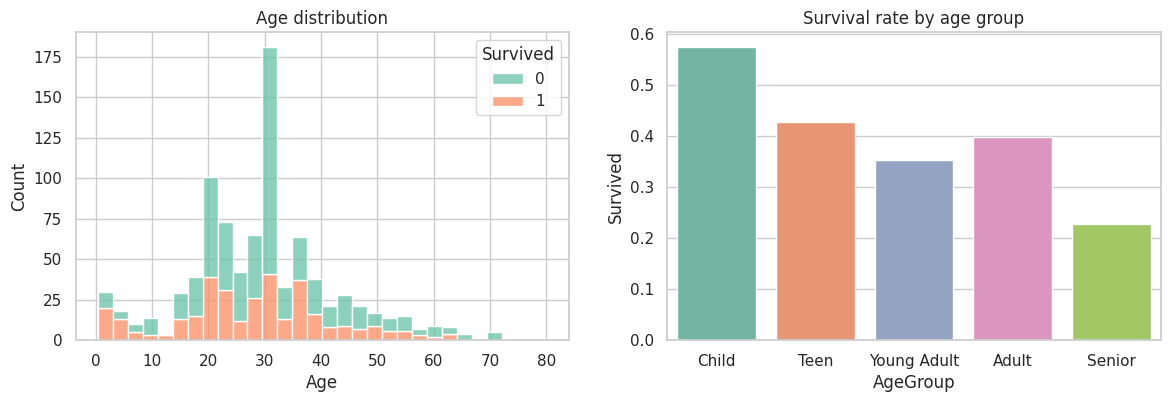

,mean,count
AgeGroup,,
Child,0.575342,73
Teen,0.428571,70
Young Adult,0.352830,530
Adult,0.397959,196
Senior,0.227273,22


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, multiple="stack", palette="Set2", ax=ax[0])
sns.barplot(data=df, x="AgeGroup", y="Survived", hue="AgeGroup", palette="Set2", errorbar=None, legend=False, ax=ax[1])
ax[0].set_title("Age distribution")
ax[1].set_title("Survival rate by age group")
plt.show()
df.groupby("AgeGroup", observed=True)["Survived"].agg(["mean", "count"])

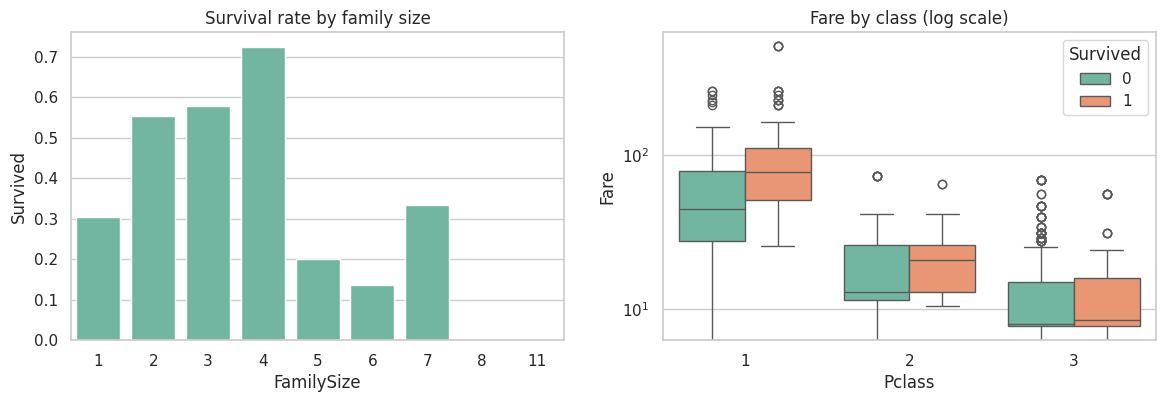

,Survived
IsAlone,
0,0.505650
1,0.303538


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=df, x="FamilySize", y="Survived", color="#66c2a5", errorbar=None, ax=ax[0])
sns.boxplot(data=df, x="Pclass", y="Fare", hue="Survived", palette="Set2", ax=ax[1])
ax[1].set_yscale("log")
ax[0].set_title("Survival rate by family size")
ax[1].set_title("Fare by class (log scale)")
plt.show()
df.groupby("IsAlone")["Survived"].mean()

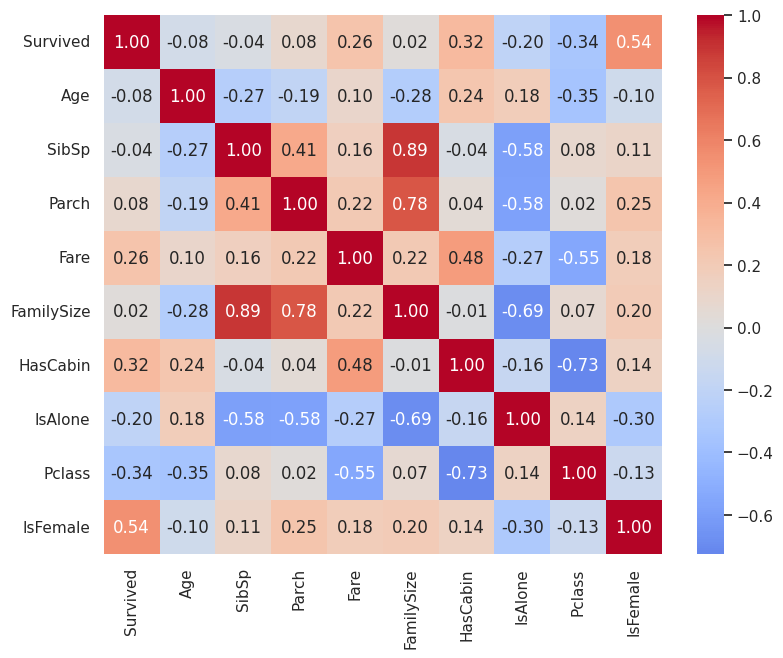

,Survived
Survived,1.000000
IsFemale,0.543351
HasCabin,0.316912
Fare,0.257307
Parch,0.081629
FamilySize,0.016639
SibSp,-0.035322
Age,-0.078931
IsAlone,-0.203367
Pclass,-0.338481


In [14]:
corr_df = df[["Survived", "Age", "SibSp", "Parch", "Fare", "FamilySize", "HasCabin", "IsAlone"]].copy()
corr_df["Pclass"] = df["Pclass"].astype(int)
corr_df["IsFemale"] = (df["Sex"] == "female").astype(int)

plt.figure(figsize=(9, 7))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()
corr_df.corr()["Survived"].sort_values(ascending=False)

## Insights
- Only 38.4% of the passengers survived (342 of 891)
- Gender was the biggest factor: 74.2% of women survived vs 18.9% of men
- Class mattered a lot too: 63% in 1st class, 47.3% in 2nd, 24.2% in 3rd
- Looking at both together, 97% of 1st class women survived but only 13.5% of 3rd class men
- Kids (12 and under) had 57.5% survival, people over 60 only 22.7%
- People travelling alone survived less (30.4%) than people with family (50.6%), but big families (5+) did badly
- Cherbourg had the highest survival (55.4%), probably because about half of the people who boarded there were 1st class. Passengers with a cabin number survived 66.7% vs 30%
- Strongest correlations with Survived: being female (0.54), HasCabin (0.32), Fare (0.26) and Pclass (-0.34)

So survival wasn't random at all, it mostly came down to gender and class.